# Домашнее задание 1. Message passing
Работу выполнила **Чендемерова Екатерина Николаевна** (S4201)

Выполненые пункты:
1. Часть 1: реализация и успешный вывод тестов
2. Часть 2: Cora и CiteSeer, GCN и MLP, не менее 5 сидов
3. Часть 3: глубины 2, 4, 8, 16 и диагностика представлений
4. Бонус A: inductive GraphSAGE
5. Бонус B: доля разметки

In [2]:
# Устанавливаем библиотеки для работы в чистом окружении
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## Часть 1: реализация и успешный вывод тестов

In [37]:
!python -m pytest tests/test_task1.py -v

============================= test session starts ==============================
platform darwin -- Python 3.13.5, pytest-8.3.4, pluggy-1.5.0 -- /opt/anaconda3/bin/python
cachedir: .pytest_cache
rootdir: /Users/kchendemer/Documents/itmo_gnn_course_labs/gnn_hw1
plugins: anyio-4.7.0
collected 7 items                                                              

tests/test_task1.py::test_gcn_output_shape PASSED                        [ 14%]
tests/test_task1.py::test_gcn_matches_pyg PASSED                         [ 28%]
tests/test_task1.py::test_gcn_on_directed_graph PASSED                   [ 42%]
tests/test_task1.py::test_gcn_permutation_invariance PASSED              [ 57%]
tests/test_task1.py::test_gcn_isolated_node_is_finite PASSED             [ 71%]
tests/test_task1.py::test_sage_matches_pyg PASSED                        [ 85%]
tests/test_task1.py::test_gcn_is_trainable PASSED                        [100%]

=============================== warnings summary ===========================

### Вывод
Реализованы слои `MyGCNConv` и `MySAGEConv` с агрегацией сообщений через `index_add_`. В GCN используются петли и нормировка по степеням вершин, в GraphSAGE усреднение признаков соседей и отдельное линейное преобразование собственных признаков.

Оба класса находятся в файле `submission.py`. Все 7 предоставленных тестов успешно пройдены.

## Часть 2: Cora и CiteSeer, GCN и MLP, не менее 5 сидов

In [3]:
# Импортируем необходимые библиотеки для работы
import random
import copy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch_geometric
import torch
from torch import nn
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.utils import subgraph
from torch_geometric.data import Data

from submission import MyGCNConv
from submission import MySAGEConv

import warnings
warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("устройство:", device)

устройство: cpu


/opt/anaconda3/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [4]:
# Загрузка датасета Сora
dataset = Planetoid(
    root="data/Planetoid",
    name="Cora",
    split="public",
    transform=NormalizeFeatures(),
)

data = dataset[0]

In [5]:
# Проверяем данные
print("Вершин:", data.num_nodes)
print("Рёбер в edge_index:", data.num_edges)
print("Признаков на вершину:", dataset.num_features)
print("Классов:", dataset.num_classes)

print("Train:", data.train_mask.sum().item())
print("Validation:", data.val_mask.sum().item())
print("Test:", data.test_mask.sum().item())

Вершин: 2708
Рёбер в edge_index: 10556
Признаков на вершину: 1433
Классов: 7
Train: 140
Validation: 500
Test: 1000


In [6]:
# Собираем двуслойнный GCN
class GCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.conv1 = MyGCNConv(in_dim, hidden_dim)
        self.conv2 = MyGCNConv(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x

In [7]:
model = GCN(
    in_dim=dataset.num_features,
    hidden_dim=16,
    out_dim=dataset.num_classes,
)

model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)

print(logits.shape)

torch.Size([2708, 7])


In [8]:
# Создаем функцию для обучения модели
def train_one_run(model_class, data, in_dim, out_dim, seed):
    torch.manual_seed(seed)

    model = model_class(
        in_dim=in_dim,
        hidden_dim=16,
        out_dim=out_dim,
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=5e-4,
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(1, 201):
        model.train()
        optimizer.zero_grad()

        logits = model(data.x, data.edge_index)
        loss = F.cross_entropy(
            logits[data.train_mask],
            data.y[data.train_mask],
        )

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            logits = model(data.x, data.edge_index)
            val_loss = F.cross_entropy(
                logits[data.val_mask],
                data.y[data.val_mask],
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        predictions = model(data.x, data.edge_index).argmax(dim=1)
        accuracy = (
            predictions[data.test_mask] == data.y[data.test_mask]
        ).float().mean().item()

    return {
        "seed": seed,
        "test_accuracy": accuracy * 100,
        "best_epoch": best_epoch,
    }

In [9]:
gcn_cora_runs = []

for seed in range(5):
    result = train_one_run(
        model_class=GCN,
        data=data,
        in_dim=dataset.num_features,
        out_dim=dataset.num_classes,
        seed=seed,
    )
    gcn_cora_runs.append(result)
    print(f"Seed {seed}: {result['test_accuracy']:.2f}%")

gcn_cora_results = pd.DataFrame(gcn_cora_runs)

mean = gcn_cora_results["test_accuracy"].mean()
std = gcn_cora_results["test_accuracy"].std(ddof=1)

print(f"\nGCN, Cora: {mean:.2f} ± {std:.2f}%")

Seed 0: 82.00%
Seed 1: 80.10%
Seed 2: 81.90%
Seed 3: 81.30%
Seed 4: 81.20%

GCN, Cora: 81.30 ± 0.76%


In [10]:
# Добавляем MLP
class MLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.lin1 = nn.Linear(in_dim, hidden_dim, bias=False)
        self.lin2 = nn.Linear(hidden_dim, out_dim, bias=False)
        self.dropout = dropout

    def forward(self, x, edge_index=None):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.lin1(x)
        x = F.relu(x)

        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.lin2(x)

In [11]:
mlp_cora_runs = []

for seed in range(5):
    result = train_one_run(
        model_class=MLP,
        data=data,
        in_dim=dataset.num_features,
        out_dim=dataset.num_classes,
        seed=seed,
    )
    mlp_cora_runs.append(result)
    print(f"Seed {seed}: {result['test_accuracy']:.2f}%")

mlp_cora_results = pd.DataFrame(mlp_cora_runs)

mean = mlp_cora_results["test_accuracy"].mean()
std = mlp_cora_results["test_accuracy"].std(ddof=1)

print(f"\nMLP, Cora: {mean:.2f} ± {std:.2f}%")

Seed 0: 55.20%
Seed 1: 52.60%
Seed 2: 57.40%
Seed 3: 55.50%
Seed 4: 56.80%

MLP, Cora: 55.50 ± 1.86%


In [12]:
# Загрузка датасета CiteSeer
citeseer_dataset = Planetoid(
    root="data/Planetoid",
    name="CiteSeer",
    split="public",
    transform=NormalizeFeatures(),
)

citeseer_data = citeseer_dataset[0]

print("Вершин:", citeseer_data.num_nodes)
print("Признаков:", citeseer_dataset.num_features)
print("Классов:", citeseer_dataset.num_classes)

Вершин: 3327
Признаков: 3703
Классов: 6


In [13]:
citeseer_runs = []

for model_name, model_class in [("GCN", GCN), ("MLP", MLP)]:
    for seed in range(5):
        result = train_one_run(
            model_class=model_class,
            data=citeseer_data,
            in_dim=citeseer_dataset.num_features,
            out_dim=citeseer_dataset.num_classes,
            seed=seed,
        )
        result["model"] = model_name
        citeseer_runs.append(result)

        print(
            f"{model_name}, seed {seed}: "
            f"{result['test_accuracy']:.2f}%"
        )

citeseer_results = pd.DataFrame(citeseer_runs)

citeseer_summary = (
    citeseer_results.groupby("model")["test_accuracy"]
    .agg(["mean", "std"])
)

print(citeseer_summary.round(2))

GCN, seed 0: 71.20%
GCN, seed 1: 70.80%
GCN, seed 2: 71.50%
GCN, seed 3: 70.50%
GCN, seed 4: 71.70%
MLP, seed 0: 57.70%
MLP, seed 1: 55.00%
MLP, seed 2: 56.50%
MLP, seed 3: 54.60%
MLP, seed 4: 57.80%
        mean   std
model             
GCN    71.14  0.49
MLP    56.32  1.49


In [14]:
# Сохранения результатов
Path("results").mkdir(exist_ok=True)

all_results = pd.concat([
    gcn_cora_results.assign(dataset="Cora", model="GCN"),
    mlp_cora_results.assign(dataset="Cora", model="MLP"),
    citeseer_results.assign(dataset="CiteSeer"),
], ignore_index=True)

all_results.to_csv("results/part2_runs.csv", index=False)

In [15]:
# Выведем таблицу результатов для вывода
stats = (
    all_results.groupby(["dataset", "model"])["test_accuracy"]
    .agg(["mean", "std"])
)

rows = []

for name, reference in [("Cora", 81.5), ("CiteSeer", 70.3)]:
    gcn = stats.loc[(name, "GCN")]
    mlp = stats.loc[(name, "MLP")]

    rows.append({
        "Датасет": name,
        "GCN, среднее ± std, %": f"{gcn['mean']:.2f} ± {gcn['std']:.2f}",
        "MLP, среднее ± std, %": f"{mlp['mean']:.2f} ± {mlp['std']:.2f}",
        "Ориентир GCN, %": f"{reference:.2f}",
        "Прирост GCN над MLP": (
            f"{gcn['mean'] - mlp['mean']:+.2f} п. п."
        ),
    })

summary_table = pd.DataFrame(rows)
display(summary_table.style.hide(axis="index"))


Датасет,"GCN, среднее ± std, %","MLP, среднее ± std, %","Ориентир GCN, %",Прирост GCN над MLP
Cora,81.30 ± 0.76,55.50 ± 1.86,81.50,+25.80 п. п.
CiteSeer,71.14 ± 0.49,56.32 ± 1.49,70.30,+14.82 п. п.


## Вывод
Двухслойная `GCN` на собственных слоях (`MyGCNConv`) и `MLP` со скрытой размерностью 16 обучены на `Cora` и `CiteSeer` со стандартным разбиением `Planetoid`. 
Для каждой модели выполнено пять запусков с разными сидами. Лучшая эпоха выбиралась по validation loss; приведены среднее и выборочное стандартное отклонение test accuracy.

GCN достигла 81.30 ± 0.76% на Cora и 71.14 ± 0.49% на CiteSeer. Отклонения от результатов Kipf & Welling, указанных в задании, составили 0.20 и 0.84 процентного пункта соответственно. Оба результата удовлетворяют критерию воспроизведения ±2 п. п.

По сравнению с MLP использование графа повысило accuracy на 25.80 п. п. на Cora и на 14.82 п. п. на CiteSeer. Это показывает, что в данном эксперименте информация о связях между вершинами существенно улучшает классификацию по сравнению с использованием только собственных признаков.

# Часть 3: глубины 2, 4, 8, 16 и диагностика представлений

In [16]:
class DeepGCN(nn.Module):
    def __init__(
        self, in_dim, hidden_dim, out_dim,
        num_layers=2, dropout=0.5,
    ):
        super().__init__()

        dims = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]

        self.convs = nn.ModuleList([
            MyGCNConv(dims[i], dims[i + 1])
            for i in range(num_layers)
        ])
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden=False):
        for conv in self.convs[:-1]:
            x = F.dropout(x, p=self.dropout, training=self.training)
            x = F.relu(conv(x, edge_index))

        hidden = x

        x = F.dropout(x, p=self.dropout, training=self.training)
        logits = self.convs[-1](x, edge_index)

        if return_hidden:
            return logits, hidden
        return logits

In [17]:
deep_model = DeepGCN(
    in_dim=dataset.num_features,
    hidden_dim=16,
    out_dim=dataset.num_classes,
    num_layers=4,
)

deep_model.eval()
with torch.no_grad():
    logits, hidden = deep_model(
        data.x, data.edge_index, return_hidden=True
    )

print("Выход:", logits.shape)
print("Скрытые представления:", hidden.shape)

Выход: torch.Size([2708, 7])
Скрытые представления: torch.Size([2708, 16])


In [18]:
@torch.no_grad()
def representation_metrics(hidden, eps=1e-8):
    norms = hidden.norm(dim=1)
    nonzero = norms > eps

    mean_norm = norms.mean().item()
    zero_fraction = (~nonzero).float().mean().item()

    # Исключаем почти нулевые векторы из расчёта сходства.
    h = hidden[nonzero]
    n = h.size(0)

    if n < 2:
        mean_cosine = float("nan")
    else:
        h = F.normalize(h, p=2, dim=1)

        # Среднее по всем парам разных вершин.
        # Формула позволяет не создавать матрицу размера n × n.
        total = h.sum(dim=0).square().sum() - h.square().sum()
        mean_cosine = (total / (n * (n - 1))).item()

    return {
        "mean_cosine": mean_cosine,
        "mean_norm": mean_norm,
        "zero_fraction": zero_fraction,
    }

In [19]:
examples = {
    "Одинаковые": torch.tensor([[1., 0.], [1., 0.]]),
    "Ортогональные": torch.tensor([[1., 0.], [0., 1.]]),
    "Нулевые": torch.zeros(2, 2),
}

for name, vectors in examples.items():
    print(name, representation_metrics(vectors))

Одинаковые {'mean_cosine': 1.0, 'mean_norm': 1.0, 'zero_fraction': 0.0}
Ортогональные {'mean_cosine': 0.0, 'mean_norm': 1.0, 'zero_fraction': 0.0}
Нулевые {'mean_cosine': nan, 'mean_norm': 0.0, 'zero_fraction': 1.0}


In [20]:
def train_depth_run(data, in_dim, out_dim, num_layers, seed):
    torch.manual_seed(seed)

    model = DeepGCN(
        in_dim=in_dim,
        hidden_dim=16,
        out_dim=out_dim,
        num_layers=num_layers,
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=5e-4,
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(1, 201):
        model.train()
        optimizer.zero_grad()

        logits = model(data.x, data.edge_index)
        loss = F.cross_entropy(
            logits[data.train_mask],
            data.y[data.train_mask],
        )
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            logits = model(data.x, data.edge_index)
            val_loss = F.cross_entropy(
                logits[data.val_mask],
                data.y[data.val_mask],
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        logits, hidden = model(
            data.x, data.edge_index, return_hidden=True
        )
        predictions = logits.argmax(dim=1)

        accuracy = (
            predictions[data.test_mask] == data.y[data.test_mask]
        ).float().mean().item()

        metrics = representation_metrics(hidden)

    return {
        "num_layers": num_layers,
        "seed": seed,
        "test_accuracy": accuracy * 100,
        "best_epoch": best_epoch,
        **metrics,
    }

In [21]:
depth_runs = []

for num_layers in [2, 4, 8, 16]:
    for seed in range(5):
        result = train_depth_run(
            data=data,
            in_dim=dataset.num_features,
            out_dim=dataset.num_classes,
            num_layers=num_layers,
            seed=seed,
        )
        depth_runs.append(result)

        print(
            f"Слоёв: {num_layers:2d}, seed: {seed} | "
            f"accuracy: {result['test_accuracy']:.2f}% | "
            f"cosine: {result['mean_cosine']:.3f} | "
            f"норма: {result['mean_norm']:.2e} | "
            f"нулевых: {result['zero_fraction']:.1%}"
        )

depth_results = pd.DataFrame(depth_runs)
depth_results.to_csv("results/part3_depth_runs.csv", index=False)

Слоёв:  2, seed: 0 | accuracy: 82.00% | cosine: 0.642 | норма: 6.28e-01 | нулевых: 0.0%
Слоёв:  2, seed: 1 | accuracy: 80.10% | cosine: 0.635 | норма: 6.16e-01 | нулевых: 0.0%
Слоёв:  2, seed: 2 | accuracy: 81.90% | cosine: 0.653 | норма: 6.28e-01 | нулевых: 0.0%
Слоёв:  2, seed: 3 | accuracy: 81.30% | cosine: 0.616 | норма: 6.05e-01 | нулевых: 0.0%
Слоёв:  2, seed: 4 | accuracy: 81.20% | cosine: 0.644 | норма: 6.24e-01 | нулевых: 0.0%
Слоёв:  4, seed: 0 | accuracy: 75.30% | cosine: 0.650 | норма: 5.64e+00 | нулевых: 0.0%
Слоёв:  4, seed: 1 | accuracy: 59.30% | cosine: 0.604 | норма: 4.59e+00 | нулевых: 0.0%
Слоёв:  4, seed: 2 | accuracy: 55.00% | cosine: 0.620 | норма: 4.25e+00 | нулевых: 0.0%
Слоёв:  4, seed: 3 | accuracy: 24.80% | cosine: 0.556 | норма: 1.50e+00 | нулевых: 0.0%
Слоёв:  4, seed: 4 | accuracy: 40.60% | cosine: 0.599 | норма: 2.41e+00 | нулевых: 2.7%
Слоёв:  8, seed: 0 | accuracy: 12.00% | cosine: 0.882 | норма: 1.19e-06 | нулевых: 0.0%
Слоёв:  8, seed: 1 | accuracy: 1

,accuracy_mean,accuracy_std,cosine_mean,cosine_std,cosine_runs
num_layers,,,,,
2,81.30,0.758,0.638,0.014,5
4,51.00,19.170,0.606,0.034,5
8,10.20,3.094,0.925,0.050,5
16,15.76,9.564,0.996,0.005,3


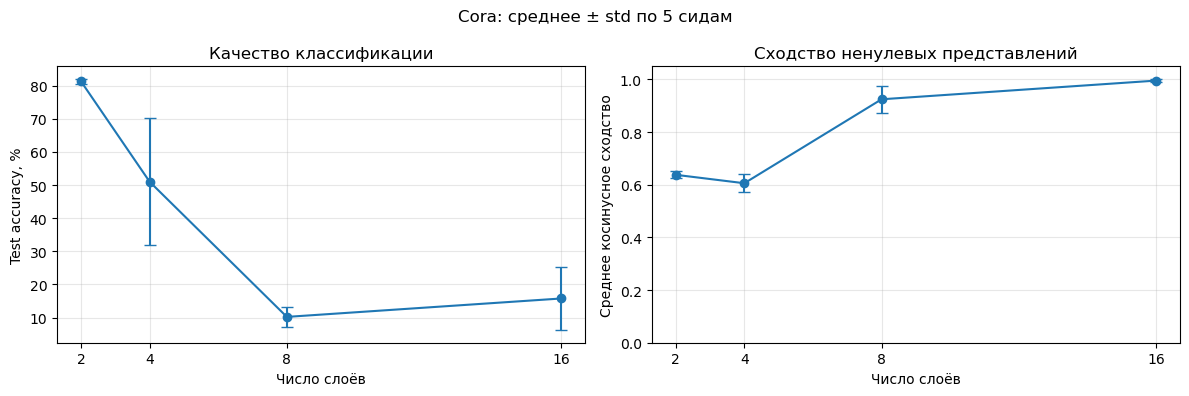

In [22]:
import matplotlib.pyplot as plt

depth_summary = (
    depth_results.groupby("num_layers")
    .agg(
        accuracy_mean=("test_accuracy", "mean"),
        accuracy_std=("test_accuracy", "std"),
        cosine_mean=("mean_cosine", "mean"),
        cosine_std=("mean_cosine", "std"),
        cosine_runs=("mean_cosine", "count"),
    )
)

display(depth_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].errorbar(
    depth_summary.index,
    depth_summary["accuracy_mean"],
    yerr=depth_summary["accuracy_std"],
    fmt="o-",
    capsize=4,
)
axes[0].set_ylabel("Test accuracy, %")
axes[0].set_title("Качество классификации")

axes[1].errorbar(
    depth_summary.index,
    depth_summary["cosine_mean"],
    yerr=depth_summary["cosine_std"],
    fmt="o-",
    capsize=4,
)
axes[1].set_ylabel("Среднее косинусное сходство")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Сходство ненулевых представлений")

for ax in axes:
    ax.set_xlabel("Число слоёв")
    ax.set_xticks([2, 4, 8, 16])
    ax.grid(alpha=0.3)

fig.suptitle("Cora: среднее ± std по 5 сидам")
plt.tight_layout()
plt.show()

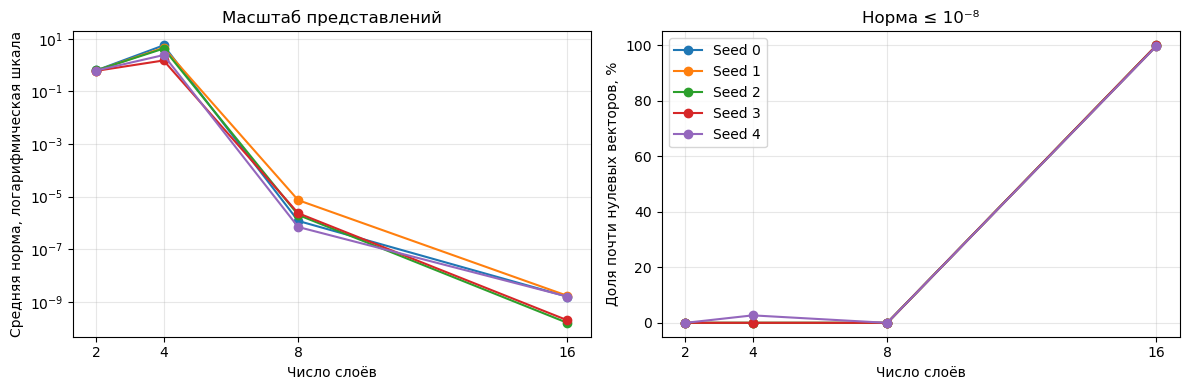

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for seed, runs in depth_results.groupby("seed"):
    runs = runs.sort_values("num_layers")

    axes[0].plot(
        runs["num_layers"],
        runs["mean_norm"],
        "o-",
        label=f"Seed {seed}",
    )
    axes[1].plot(
        runs["num_layers"],
        runs["zero_fraction"] * 100,
        "o-",
        label=f"Seed {seed}",
    )

axes[0].set_yscale("log")
axes[0].set_ylabel("Средняя норма, логарифмическая шкала")
axes[0].set_title("Масштаб представлений")

axes[1].set_ylabel("Доля почти нулевых векторов, %")
axes[1].set_title("Норма ≤ 10⁻⁸")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Число слоёв")
    ax.set_xticks([2, 4, 8, 16])
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Вывод по части 3

На `Cora` обучены `GCN` глубиной 2, 4, 8 и 16 слоёв, по пять запусков для каждой глубины. Диагностика выполнена на последнем скрытом слое модели, выбранной по validation loss, с отключённым dropout.

При *двух слоях* средняя accuracy составляет **81.30%**. При *четырёх слоях* качество снижается и сильно зависит от сида, однако среднее косинусное сходство не увеличивается. Поэтому ухудшение на этой глубине нельзя объяснить слипанием представлений.

При *восьми слоях* среднее сходство возрастает примерно до **0.93**, одновременно нормы представлений уменьшаются до порядка $10^{-6}$. Наблюдаются и сближение направлений векторов, и сильное затухание активаций.

При шестнадцати слоях 99.7–100% векторов имеют норму не выше $10^{-8}$. Значения сходства около 1 рассчитаны лишь по небольшой оставшейся группе вершин; в двух запусках сходство не определено. Следовательно, эта точка графика не доказывает слипание представлений всего графа: основной наблюдаемый эффект — почти полное зануление активаций и низкое качество классификации.

Таким образом, увеличение глубины в данной архитектуре и при выбранных настройках приводит к нестабильному обучению и последующему затуханию представлений. Точную причину затухания — например, поведение градиентов или влияние регуляризации — эти измерения отдельно не устанавливают.

## Бонус A: inductive GraphSAGE

In [24]:
# Новые вершины, которые модель не должна видеть при обучении
new_nodes = data.test_mask.nonzero(as_tuple=True)[0]
assert new_nodes.numel() == 1000

# Оставляем все остальные вершины
keep_mask = ~data.test_mask

train_edge_index, _ = subgraph(
    subset=keep_mask,
    edge_index=data.edge_index,
    relabel_nodes=True,
    num_nodes=data.num_nodes,
)

In [25]:
inductive_data = Data(
    x=data.x[keep_mask],
    y=data.y[keep_mask],
    edge_index=train_edge_index,
    train_mask=data.train_mask[keep_mask],
    val_mask=data.val_mask[keep_mask],
)

print("Полный граф:", data.num_nodes, "вершин")
print("Обучающий подграф:", inductive_data.num_nodes, "вершин")
print("Train:", inductive_data.train_mask.sum().item())
print("Validation:", inductive_data.val_mask.sum().item())

Полный граф: 2708 вершин
Обучающий подграф: 1708 вершин
Train: 140
Validation: 500


In [26]:
# Собираем двуслойную GraphSAGE

class GraphSAGE(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.conv1 = MySAGEConv(in_dim, hidden_dim)
        self.conv2 = MySAGEConv(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.conv1(x, edge_index))

        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

In [27]:
sage = GraphSAGE(
    in_dim=dataset.num_features,
    hidden_dim=16,
    out_dim=dataset.num_classes,
)

sage.eval()
with torch.no_grad():
    subgraph_logits = sage(
        inductive_data.x, inductive_data.edge_index
    )
    full_logits = sage(data.x, data.edge_index)

print("Подграф:", subgraph_logits.shape)
print("Полный граф:", full_logits.shape)

Подграф: torch.Size([1708, 7])
Полный граф: torch.Size([2708, 7])


In [28]:
def train_sage_run(train_data, full_data, new_nodes, seed):
    torch.manual_seed(seed)

    model = GraphSAGE(
        in_dim=full_data.num_node_features,
        hidden_dim=16,
        out_dim=int(full_data.y.max().item()) + 1,
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=5e-4,
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(1, 201):
        model.train()
        optimizer.zero_grad()

        logits = model(train_data.x, train_data.edge_index)
        loss = F.cross_entropy(
            logits[train_data.train_mask],
            train_data.y[train_data.train_mask],
        )
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            logits = model(train_data.x, train_data.edge_index)
            val_loss = F.cross_entropy(
                logits[train_data.val_mask],
                train_data.y[train_data.val_mask],
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

    model.load_state_dict(best_state)
    model.eval()

    # Полный граф используется для итоговой оценки без дообучения
    with torch.no_grad():
        logits = model(full_data.x, full_data.edge_index)
        predictions = logits.argmax(dim=1)

        accuracy = (
            predictions[new_nodes] == full_data.y[new_nodes]
        ).float().mean().item()

    return {
        "seed": seed,
        "test_accuracy": accuracy * 100,
        "best_epoch": best_epoch,
    }

In [29]:
sage_runs = []

for mode, train_graph in [
    ("inductive", inductive_data),
    ("transductive", data),
]:
    for seed in range(5):
        result = train_sage_run(
            train_data=train_graph,
            full_data=data,
            new_nodes=new_nodes,
            seed=seed,
        )
        result["mode"] = mode
        sage_runs.append(result)

        print(
            f"{mode}, seed {seed}: "
            f"{result['test_accuracy']:.2f}%"
        )

sage_results = pd.DataFrame(sage_runs)
sage_results.to_csv("results/bonus_a_runs.csv", index=False)

inductive, seed 0: 81.10%
inductive, seed 1: 79.90%
inductive, seed 2: 79.90%
inductive, seed 3: 80.30%
inductive, seed 4: 79.40%
transductive, seed 0: 81.70%
transductive, seed 1: 81.10%
transductive, seed 2: 81.00%
transductive, seed 3: 81.70%
transductive, seed 4: 80.50%


In [30]:
sage_summary = (
    sage_results.groupby("mode")["test_accuracy"]
    .agg(["mean", "std"])
    .reindex(["inductive", "transductive"])
)

table = pd.DataFrame({
    "Режим": sage_summary.index,
    "Видела ли модель новые вершины при обучении?": [
        "Нет",
        "Да, но без меток",
    ],
    "Accuracy, среднее ± std, %": [
        f"{row['mean']:.2f} ± {row['std']:.2f}"
        for _, row in sage_summary.iterrows()
    ],
})

display(table.style.hide(axis="index"))

Режим,Видела ли модель новые вершины при обучении?,"Accuracy, среднее ± std, %"
inductive,Нет,80.12 ± 0.63
transductive,"Да, но без меток",81.20 ± 0.51


### Вывод Бонус А
На Cora GraphSAGE достигла accuracy 80.12 ± 0.63% в inductive-режиме и 81.20 ± 0.51% в transductive-режиме по пяти сидам; указаны среднее и выборочное стандартное отклонение. Отсутствие новых вершин и их рёбер при обучении снизило среднюю accuracy на 1.08 процентного пункта: в transductive-режиме их признаки и связи участвуют в передаче сообщений и влияют на обучение, хотя метки скрыты. При этом inductive-модель успешно обработала новые вершины без дообучения, применив к ним общие обученные преобразования GraphSAGE.

## Бонус B: доля разметки

In [31]:
# Копия графа: стандартные маски исходного data не изменяем
label_data = data.clone()

split_generator = torch.Generator().manual_seed(42)
permutation = torch.randperm(
    label_data.num_nodes,
    generator=split_generator,
)

val_nodes = permutation[:300]
test_nodes = permutation[300:800]
train_pool = permutation[800:]

label_data.val_mask = torch.zeros(
    label_data.num_nodes, dtype=torch.bool
)
label_data.test_mask = torch.zeros(
    label_data.num_nodes, dtype=torch.bool
)

label_data.val_mask[val_nodes] = True
label_data.test_mask[test_nodes] = True

print("Validation:", label_data.val_mask.sum().item())
print("Test:", label_data.test_mask.sum().item())
print("Кандидатов для обучения:", train_pool.numel())

Validation: 300
Test: 500
Кандидатов для обучения: 1908


In [32]:
# Создадим функцию, которая выбирает обучающие вершины для нужной доли разметки
def make_label_split(fraction, seed):
    experiment_data = label_data.clone()

    generator = torch.Generator().manual_seed(seed)
    order = torch.randperm(
        train_pool.numel(),
        generator=generator,
    )
    shuffled_pool = train_pool[order]

    # Доля считается от всех вершин графа.
    num_train = round(fraction * label_data.num_nodes)
    assert num_train <= train_pool.numel()

    selected = shuffled_pool[:num_train]

    experiment_data.train_mask = torch.zeros(
        label_data.num_nodes, dtype=torch.bool
    )
    experiment_data.train_mask[selected] = True

    # Проверяем отсутствие пересечений.
    assert not (
        experiment_data.train_mask & experiment_data.val_mask
    ).any()
    assert not (
        experiment_data.train_mask & experiment_data.test_mask
    ).any()

    return experiment_data

In [33]:
# Проверим размеры
fractions = [0.01, 0.05, 0.20, 0.60]

for fraction in fractions:
    experiment_data = make_label_split(fraction, seed=0)

    print(
        f"Разметка {fraction:.0%}: "
        f"{experiment_data.train_mask.sum().item()} вершин"
    )

Разметка 1%: 27 вершин
Разметка 5%: 135 вершин
Разметка 20%: 542 вершин
Разметка 60%: 1625 вершин


In [34]:
label_runs = []

for fraction in fractions:
    for seed in range(5):
        experiment_data = make_label_split(fraction, seed)

        for model_name, model_class in [("GCN", GCN), ("MLP", MLP)]:
            result = train_one_run(
                model_class=model_class,
                data=experiment_data,
                in_dim=dataset.num_features,
                out_dim=dataset.num_classes,
                seed=seed,
            )

            result["model"] = model_name
            result["label_fraction"] = fraction
            result["num_train"] = (
                experiment_data.train_mask.sum().item()
            )
            label_runs.append(result)

            print(
                f"Разметка {fraction:.0%}, "
                f"{model_name}, seed {seed}: "
                f"{result['test_accuracy']:.2f}%"
            )

label_results = pd.DataFrame(label_runs)
label_results.to_csv("results/bonus_b_runs.csv", index=False)

Разметка 1%, GCN, seed 0: 63.20%
Разметка 1%, MLP, seed 0: 38.60%
Разметка 1%, GCN, seed 1: 61.40%
Разметка 1%, MLP, seed 1: 39.60%
Разметка 1%, GCN, seed 2: 50.60%
Разметка 1%, MLP, seed 2: 35.40%
Разметка 1%, GCN, seed 3: 63.20%
Разметка 1%, MLP, seed 3: 37.40%
Разметка 1%, GCN, seed 4: 54.20%
Разметка 1%, MLP, seed 4: 37.60%
Разметка 5%, GCN, seed 0: 74.40%
Разметка 5%, MLP, seed 0: 52.00%
Разметка 5%, GCN, seed 1: 73.20%
Разметка 5%, MLP, seed 1: 49.80%
Разметка 5%, GCN, seed 2: 77.40%
Разметка 5%, MLP, seed 2: 51.20%
Разметка 5%, GCN, seed 3: 78.40%
Разметка 5%, MLP, seed 3: 55.00%
Разметка 5%, GCN, seed 4: 78.60%
Разметка 5%, MLP, seed 4: 55.20%
Разметка 20%, GCN, seed 0: 84.00%
Разметка 20%, MLP, seed 0: 66.80%
Разметка 20%, GCN, seed 1: 83.00%
Разметка 20%, MLP, seed 1: 67.00%
Разметка 20%, GCN, seed 2: 79.00%
Разметка 20%, MLP, seed 2: 62.00%
Разметка 20%, GCN, seed 3: 84.40%
Разметка 20%, MLP, seed 3: 67.20%
Разметка 20%, GCN, seed 4: 81.80%
Разметка 20%, MLP, seed 4: 66.20%


In [35]:
label_summary = (
    label_results.groupby(["label_fraction", "model"])["test_accuracy"]
    .agg(["mean", "std"])
    .round(2)
)

display(label_summary)

mean   std
label_fraction model             
0.01           GCN    58.52  5.78
               MLP    37.72  1.57
0.05           GCN    76.40  2.45
               MLP    52.64  2.38
0.20           GCN    82.44  2.17
               MLP    65.84  2.18
0.60           GCN    86.56  0.38
               MLP    71.68  0.94

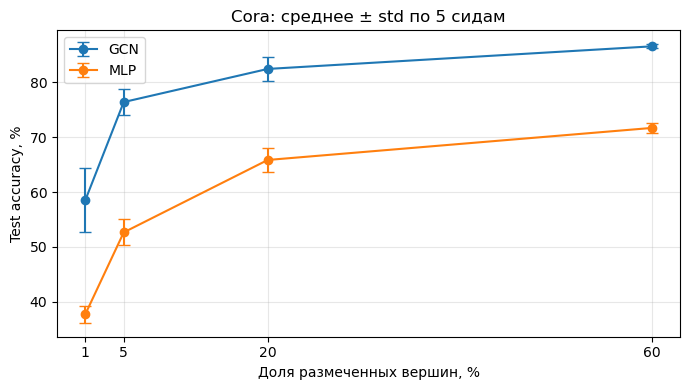

In [36]:
fig, ax = plt.subplots(figsize=(7, 4))

for model_name in ["GCN", "MLP"]:
    model_stats = label_summary.xs(model_name, level="model")

    ax.errorbar(
        model_stats.index * 100,
        model_stats["mean"],
        yerr=model_stats["std"],
        fmt="o-",
        capsize=4,
        label=model_name,
    )

ax.set_xlabel("Доля размеченных вершин, %")
ax.set_ylabel("Test accuracy, %")
ax.set_title("Cora: среднее ± std по 5 сидам")
ax.set_xticks([1, 5, 20, 60])
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Вывод Бонус B
Для эксперимента использовано отдельное фиксированное разбиение Cora: 300 вершин для validation и 500 для test. Доля разметки считалась от всех 2708 вершин графа; обучающие вершины выбирались вне validation/test. Для каждой доли выполнено пять запусков, причём GCN и MLP получали одинаковые обучающие маски.

При увеличении доли разметки с 1% до 60% средняя accuracy GCN выросла с 58.52% до 86.56%, а MLP — с 37.72% до 71.68%. Преимущество GCN составило 20.80, 23.76, 16.60 и 14.88 процентного пункта при 1%, 5%, 20% и 60% разметки соответственно.

На проверенных долях преимущество графа не исчезло. После 5% разметки разрыв сокращается: дополнительные метки помогают MLP лучше использовать собственные признаки вершин, однако информация о соседях остаётся полезной для GCN. Определить долю, при которой преимущество исчезает, по этим результатам нельзя.